# Working with Data

## Exploring One-Dimensional Data

One-dimensional data = just one list of numbers, example daily sales, marks of students, minutes spent on an app.

### Step 1: summary statistics
Count, minimum, maximum, mean, standard deviation.

### Step 2: a histogram
Summary numbers don't tell the full story. A histogram groups the numbers into buckets and shows how many fall in each.

### Example: monthly profit / loss of two shops (thousand Rupees) 
- Shop A: any value between −100 and +100 is equally likely (uniform)
- Shop B: most months are near 0, with a few big wins or losses (normal)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import math
import random
import csv
from collections import Counter, defaultdict
from functools import partial, reduce
from datetime import date, datetime, timedelta
from pathlib import Path

In [3]:
def dot(v, w):            return sum(v_i * w_i for v_i, w_i in zip(v, w))
def vector_subtract(v, w): return [v_i - w_i for v_i, w_i in zip(v, w)]
def vector_sum(vectors):  return reduce(lambda v, w: [a + b for a, b in zip(v, w)], vectors)
def scalar_multiply(c, v): return [c * v_i for v_i in v]
def magnitude(v):         return math.sqrt(dot(v, v))
def distance(v, w):       return magnitude(vector_subtract(v, w))
def shape(A):             return len(A), len(A[0]) if A else 0
def get_column(A, j):     return [row[j] for row in A]
def make_matrix(num_rows, num_cols, entry_fn):
    return [[entry_fn(i, j) for j in range(num_cols)] for i in range(num_rows)]

def mean(x):               return sum(x) / len(x)
def de_mean(x):            m = mean(x); return [x_i - m for x_i in x]
def variance(x):           return sum(d ** 2 for d in de_mean(x)) / (len(x) - 1)
def standard_deviation(x): return math.sqrt(variance(x))
def covariance(x, y):      return dot(de_mean(x), de_mean(y)) / (len(x) - 1)
def correlation(x, y):
    sx, sy = standard_deviation(x), standard_deviation(y)
    return covariance(x, y) / sx / sy if sx > 0 and sy > 0 else 0

def step(v, direction, step_size):
    return [v_i + step_size * d_i for v_i, d_i in zip(v, direction)]

def safe(f):
    def safe_f(*args, **kwargs):
        try:
            return f(*args, **kwargs)
        except Exception:
            return float("inf")
    return safe_f

def minimize_batch(target_fn, gradient_fn, theta_0, tolerance=0.000001):
    step_sizes = [100, 10, 1, 0.1, 0.01, 0.001, 0.0001, 0.00001]
    theta, target_fn = theta_0, safe(target_fn)
    value = target_fn(theta)
    while True:
        gradient = gradient_fn(theta)
        next_thetas = [step(theta, gradient, -s) for s in step_sizes]
        next_theta = min(next_thetas, key=target_fn)
        next_value = target_fn(next_theta)
        if abs(value - next_value) < tolerance:
            return theta
        theta, value = next_theta, next_value

def negate(f):     return lambda *args, **kwargs: -f(*args, **kwargs)
def negate_all(f): return lambda *args, **kwargs: [-y for y in f(*args, **kwargs)]
def maximize_batch(target_fn, gradient_fn, theta_0, tolerance=0.000001):
    return minimize_batch(negate(target_fn), negate_all(gradient_fn), theta_0, tolerance)

In [4]:
def bucketize(point, bucket_size):
    """Round the point DOWN to the nearest multiple of bucket_size, e.g. 37 -> 30"""
    return bucket_size * math.floor(point / bucket_size)

def make_histogram(points, bucket_size):
    """Put the points into buckets and count how many are in each"""
    return Counter(bucketize(point, bucket_size) for point in points)

random.seed(0)
shop_a = [200 * random.random() - 100 for _ in range(10000)]   # uniform between -100 and 100
shop_b = [random.gauss(0, 57.7) for _ in range(10000)]         # normal: mean 0, sd 57.7

for name, data in [("Shop A", shop_a), ("Shop B", shop_b)]:
    print(f"{name}: count={len(data)}, min={min(data):7.1f}, max={max(data):6.1f}, "
          f"mean={mean(data):5.2f}, sd={standard_deviation(data):5.2f}")

hist_a = make_histogram(shop_a, 10)
print("\nShop A, first few buckets:", sorted(hist_a.items())[:4])

Shop A: count=10000, min= -100.0, max= 100.0, mean= 0.13, sd=57.56
Shop B: count=10000, min= -208.2, max= 228.8, mean= 0.57, sd=56.97

Shop A, first few buckets: [(-100, 542), (-90, 484), (-80, 468), (-70, 489)]


In [5]:
rng = np.random.default_rng(0)
a = rng.uniform(-100, 100, 10000)
b = rng.normal(0, 57.7, 10000)

# NumPy: summary stats and bucketing
print("NumPy  Shop A: mean =", a.mean().round(2), "| sd =", a.std(ddof=1).round(2))
print("NumPy  Shop B: mean =", b.mean().round(2), "| sd =", b.std(ddof=1).round(2))
buckets = 10 * np.floor(a / 10)                       # the same bucketize idea, on a whole array
counts, edges = np.histogram(a, bins=np.arange(-100, 101, 10))
print("NumPy  Shop A, first 4 bucket counts:", counts[:4])

# pandas: describe() gives all the summary stats in one go
shops = pd.DataFrame({"Shop A": a, "Shop B": b})
print("\npandas describe():")
print(shops.describe().round(1))

NumPy  Shop A: mean = -0.12 | sd = 57.81
NumPy  Shop B: mean = 0.26 | sd = 57.27
NumPy  Shop A, first 4 bucket counts: [503 530 498 518]

pandas describe():
        Shop A   Shop B
count  10000.0  10000.0
mean      -0.1      0.3
std       57.8     57.3
min     -100.0   -232.1
25%      -50.3    -38.4
50%        0.2     -0.1
75%       50.1     39.5
max      100.0    227.7


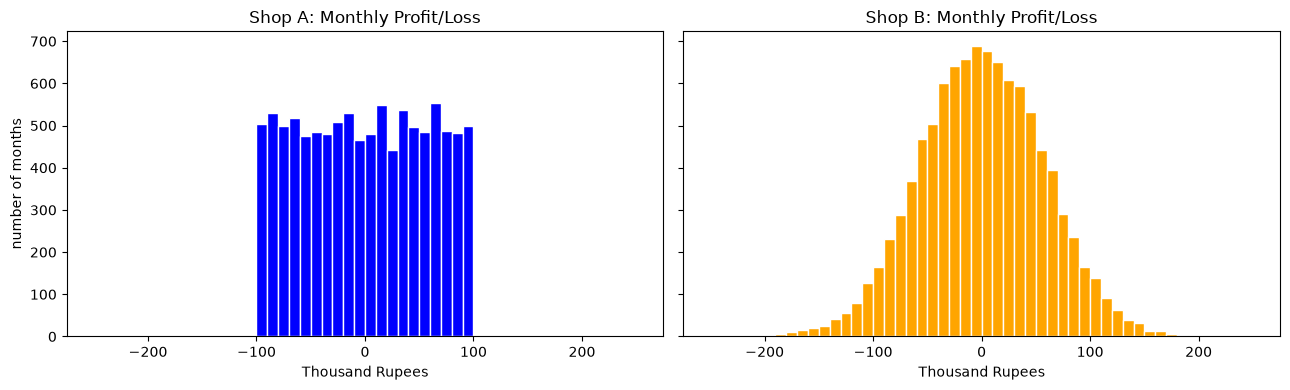

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, color) in zip(axes, [("Shop A", 'blue'), ("Shop B", 'orange')]):
    shops[name].plot.hist(ax=ax, bins=np.arange(-250, 251, 10), color=color, edgecolor="white")
    ax.set_title(f"{name}: Monthly Profit/Loss")
    ax.set_xlabel("Thousand Rupees")
axes[0].set_ylabel("number of months")
plt.tight_layout()
plt.show()

### Exploring Two Dimensions

With two columns, look at each one alone (histogram), and also look at them together (scatterplot).

### Example:
For 1,000 days we have:
- temperature (°C)
- cold drinks sold: more on hot days
- hot tea sold: fewer on hot days

In [8]:
rng = np.random.default_rng(1)
temperature = rng.normal(30, 4, 1000)                               # °C
cold_drinks = np.clip(200 + 10 * (temperature - 30) + rng.normal(0, 20, 1000), 0, None)
hot_tea     = np.clip(200 - 10 * (temperature - 30) + rng.normal(0, 20, 1000), 0, None)   # sales can't be negative

canteen = pd.DataFrame({"temperature": temperature,
                        "cold_drinks": cold_drinks,
                        "hot_tea": hot_tea})
print(canteen.describe().loc[["mean", "std"]].round(1))

      temperature  cold_drinks  hot_tea
mean         29.8        198.4    202.6
std           3.9         45.2     44.5
